# Task 1

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
print("my name")

In [2]:
digits = load_digits()
X, y = digits.data, digits.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

noise_cols = [0, 50, 200, 1000, 5000]
results = []

In [3]:
print(f"N of datasets = {len(X)}")
print(f"D of datasets = {len(y)}")
print(f"Training set shape (X, y): ", X_train.shape, y_train.shape)
print(f"Testing set shape: ", X_test.shape, y_test.shape)

N of datasets = 1797
D of datasets = 1797
Training set shape (X, y):  (1437, 64) (1437,)
Testing set shape:  (360, 64) (360,)


In [4]:
for n_cols in noise_cols:
    if n_cols > 0:
        noise_train = np.random.uniform(0, 16, (X_train.shape[0], n_cols))
        noise_test = np.random.uniform(0, 16, (X_test.shape[0], n_cols))
        X_train_n = np.hstack((X_train, noise_train))
        X_test_n = np.hstack((X_test, noise_test))
    else:
        X_train_n, X_test_n = X_train.copy(), X_test.copy()
        
    knn = KNeighborsClassifier(n_neighbors=5)
    knn.fit(X_train_n, y_train)
    
    start_time = time.time()
    acc = knn.score(X_test_n, y_test)
    predict_time = (time.time() - start_time) 
    
    mem_kb = X_train_n.nbytes / 1024 / 1024
    
    results.append({
        "Noise columns": n_cols,
        "D": X_train_n.shape[1],
        "Accuracy (%)": round(acc * 100, 2),
        "predict_time (s)": round(predict_time, 4),
        "Memory (KMB)": round(mem_kb, 3)
    })

 Noise columns    D  Accuracy (%)  predict_time (s)  Memory (KMB)
             0   64         98.61            1.4173         0.702
            50  114         97.50            0.0022         1.250
           200  264         91.39            0.0026         2.894
          1000 1064         64.72            0.0071        11.665
          5000 5064         30.00            0.0285        55.519


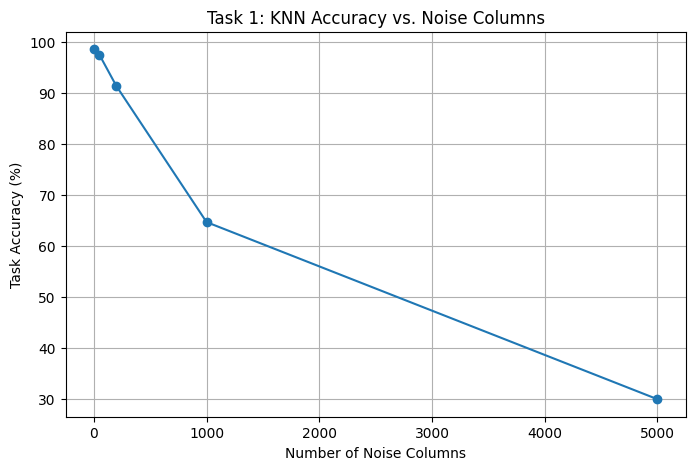

In [5]:
df = pd.DataFrame(results)
print(df.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.plot(df["Noise columns"], df["Accuracy (%)"], marker='o')
plt.xlabel("Number of Noise Columns")
plt.ylabel("Task Accuracy (%)")
plt.title("Task 1: KNN Accuracy vs. Noise Columns")
plt.grid(True)
plt.show()

# Task 2

In [6]:
from scipy.spatial.distance import cdist

In [7]:
dimensions = [2, 10, 100, 1000, 10000]

def compute_contrast(N, dims, metric='euclidean'):
    contrasts = []
    for D in dims:
        points = np.random.rand(N, D)
        query = np.random.rand(1, D)
        
        distances = cdist(query, points, metric=metric)[0]
        d_min, d_max = np.min(distances), np.max(distances)
        
        contrast = (d_max - d_min) / d_min
        contrasts.append(contrast)
        
    return contrasts

In [8]:
contrast_500_euc = compute_contrast(500, dimensions, metric='euclidean')
contrast_5000_euc = compute_contrast(5000, dimensions, metric='euclidean')
contrast_500_man = compute_contrast(500, dimensions, metric="cityblock")
contrast_5000_man = compute_contrast(5000, dimensions, metric='cityblock')

print(f"{'D':>5} | {'N=500 (L2)':>12} | {'N=5000 (L2)':>13} | {'N=500 (L1)':>12} | {'N=5000 (L1)':>12}")
print("-" * 65)
for i, D in enumerate(dimensions):
    print(f"{D:>5} | {contrast_500_euc[i]:>12.4f} | {contrast_5000_euc[i]:>13.4f} | {contrast_500_man[i]:>12.4f} | {contrast_5000_man[i]:>12.4f}")

    D |   N=500 (L2) |   N=5000 (L2) |   N=500 (L1) |  N=5000 (L1)
-----------------------------------------------------------------
    2 |      77.0532 |      154.9545 |      76.5956 |      91.8246
   10 |       2.7287 |        3.5865 |       2.6223 |       4.8789
  100 |       0.4024 |        0.4917 |       0.5670 |       0.6074
 1000 |       0.1112 |        0.1396 |       0.1361 |       0.1714
10000 |       0.0328 |        0.0411 |       0.0437 |       0.0570


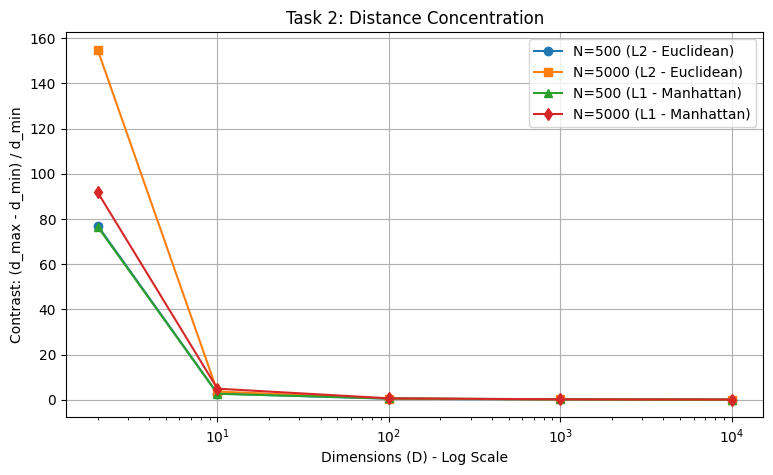

In [9]:
plt.figure(figsize=(9, 5))
plt.plot(dimensions, contrast_500_euc, marker='o', label='N=500 (L2 - Euclidean)')
plt.plot(dimensions, contrast_5000_euc, marker='s', label='N=5000 (L2 - Euclidean)')
plt.plot(dimensions, contrast_500_man, marker='^', label='N=500 (L1 - Manhattan)')
plt.plot(dimensions, contrast_5000_man, marker='d', label='N=5000 (L1 - Manhattan)')

plt.xscale('log')
plt.xlabel('Dimensions (D) - Log Scale')
plt.ylabel('Contrast: (d_max - d_min) / d_min')
plt.title('Task 2: Distance Concentration')
plt.legend()
plt.grid(True)
plt.show()

# Task 3

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.feature_selection import VarianceThreshold

In [11]:
digits = load_digits()
X, y = digits.data, digits.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

def evaluate_subset(X_tr, X_te, y_tr, y_te, seed=42):
    """Trains classifier and measures accuracy (%), training time (ms), and data memory (KB)."""
    clf = RandomForestClassifier(n_estimators=100, random_state=seed)
    
    start_time = time.perf_counter()
    clf.fit(X_tr, y_tr)
    train_time_ms = (time.perf_counter() - start_time) * 1000.0
    
    preds = clf.predict(X_te)
    acc_pct = accuracy_score(y_te, preds) * 100.0
    
    memory_kb = (X_tr.nbytes + X_te.nbytes) / 1024.0
    return acc_pct, train_time_ms, memory_kb

base_acc, base_time, base_mem = evaluate_subset(X_train, X_test, y_train, y_test)

In [12]:
var_thresh_val = 22.0
selector = VarianceThreshold(threshold=var_thresh_val)
X_train_var = selector.fit_transform(X_train)
X_test_var = selector.transform(X_test)
var_cols = X_train_var.shape[1]
var_acc, var_time, var_mem = evaluate_subset(X_train_var, X_test_var, y_train, y_test)

corr_matrix = pd.DataFrame(X_train).corr().abs().fillna(0)
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper_tri.columns if any(upper_tri[col] > 0.9)]

X_train_corr = np.delete(X_train, to_drop, axis=1)
X_test_corr = np.delete(X_test, to_drop, axis=1)
corr_cols = X_train_corr.shape[1]
corr_acc, corr_time, corr_mem = evaluate_subset(X_train_corr, X_test_corr, y_train, y_test)

In [13]:
rng = np.random.RandomState(42)
rand_accs, rand_times, rand_mems = [], [], []

for i in range(10):
    cols = rng.choice(X_train.shape[1], size=16, replace=False)
    acc, t_ms, mem = evaluate_subset(X_train[:, cols], X_test[:, cols], y_train, y_test, seed=42+i)
    rand_accs.append(acc)
    rand_times.append(t_ms)
    rand_mems.append(mem)

rand_acc_mean, rand_acc_std = np.mean(rand_accs), np.std(rand_accs)
rand_time_mean = np.mean(rand_times)
rand_mem_mean = np.mean(rand_mems)

In [14]:
#Summary Table
print(f"Baseline (64 cols)              : Acc = {base_acc:.2f}%                     | Time = {base_time:.1f} ms | Mem = {base_mem:.1f} KB")
print(f"Variance (Thresh={var_thresh_val}, {var_cols} cols) : Acc = {var_acc:.2f}% ({var_acc - base_acc:+.2f} pp)          | Time = {var_time:.1f} ms | Mem = {var_mem:.1f} KB")
print(f"Correlation (>0.9, {corr_cols} cols)     : Acc = {corr_acc:.2f}% ({corr_acc - base_acc:+.2f} pp)          | Time = {corr_time:.1f} ms | Mem = {corr_mem:.1f} KB")
print(f"Random (16 cols, 10x)           : Acc = {rand_acc_mean:.2f}% ± {rand_acc_std:.2f}% ({rand_acc_mean - base_acc:+.2f} pp) | Time = {rand_time_mean:.1f} ms | Mem = {rand_mem_mean:.1f} KB")

Baseline (64 cols)              : Acc = 96.11%                     | Time = 179.8 ms | Mem = 898.5 KB
Variance (Thresh=22.0, 29 cols) : Acc = 96.11% (+0.00 pp)          | Time = 175.9 ms | Mem = 407.1 KB
Correlation (>0.9, 63 cols)     : Acc = 97.22% (+1.11 pp)          | Time = 163.9 ms | Mem = 884.5 KB
Random (16 cols, 10x)           : Acc = 85.67% ± 4.43% (-10.44 pp) | Time = 139.5 ms | Mem = 224.6 KB
